<a href="https://colab.research.google.com/github/celinekm/CN/blob/main/tarefaGauss_celine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Número de iterações: 6
Solução aproximada (x, y, z): [ 1.00000003  1.99999998 -1.00000001]

Tabela: k, x, y, z, erro infinito
 1  0.6000000000  2.0545454545  -0.9145454545  2.0545454545e+00
 2  0.9883636364  2.0067107438  -0.9970016529  3.8836363636e-01
 3  1.0000714050  2.0002790684  -0.9999863742  1.1707768595e-02
 4  1.0000251817  2.0000035280  -1.0000046835  2.7554041391e-04
 5  1.0000012895  1.9999996915  -1.0000002888  2.3892164743e-05
 6  1.0000000269  1.9999999762  -1.0000000078  1.2626069386e-06


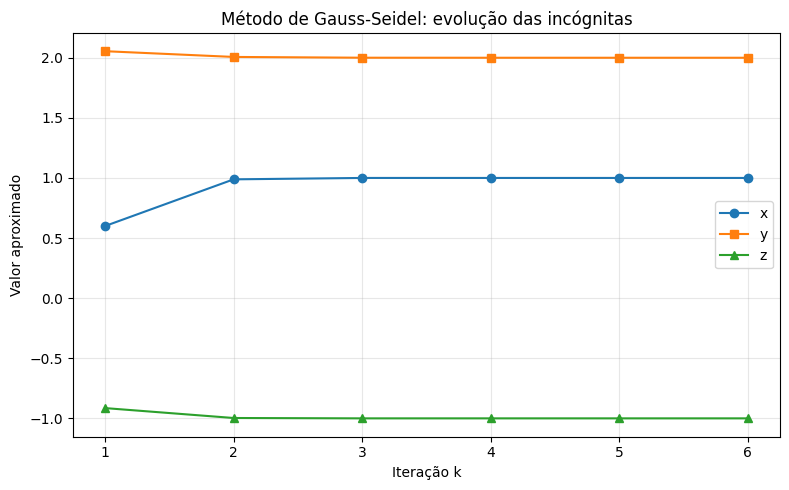

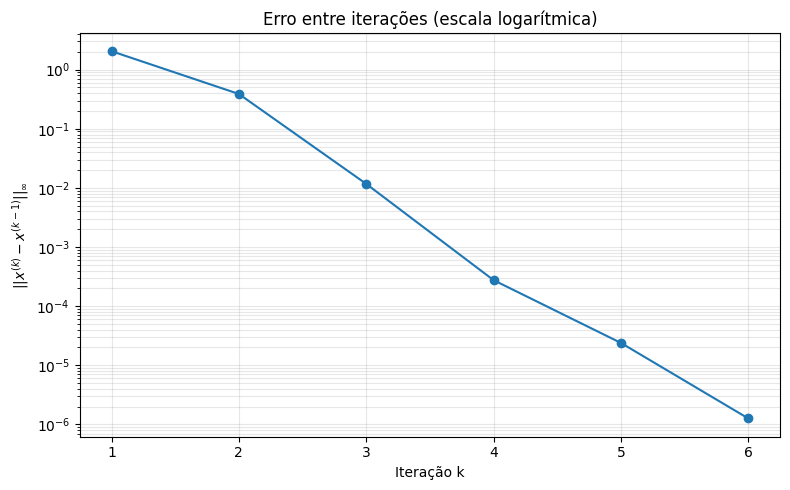

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Sistema A x = b
A = np.array([
    [10.0, -1.0,  2.0],
    [-1.0, 11.0, -1.0],
    [ 2.0, -1.0, 10.0]
])
b = np.array([6.0, 22.0, -10.0])

def gauss_seidel(tol=1e-5, max_iter=1000):
    x = np.zeros(3)  # x^(0) = (0, 0, 0)
    historico = []
    for k in range(1, max_iter + 1):
        anterior = x.copy()

        # Gauss-Seidel: usar imediatamente os valores atualizados
        x[0] = (6 + anterior[1] - 2 * anterior[2]) / 10
        x[1] = (22 + x[0] + anterior[2]) / 11
        x[2] = (-10 - 2 * x[0] + x[1]) / 10

        erro = np.max(np.abs(x - anterior))
        historico.append([k, x[0], x[1], x[2], erro])
        if erro < tol:
            break

    return np.array(historico)

dados = gauss_seidel()
print("Número de iterações:", len(dados))
print("Solução aproximada (x, y, z):", dados[-1, 1:4])
print("\nTabela: k, x, y, z, erro infinito")
for linha in dados:
    print(f"{int(linha[0]):2d}  {linha[1]:.10f}  {linha[2]:.10f}  "
          f"{linha[3]:.10f}  {linha[4]:.10e}")

# Gráfico das aproximações
plt.figure(figsize=(8, 5))
plt.plot(dados[:, 0], dados[:, 1], marker="o", label="x")
plt.plot(dados[:, 0], dados[:, 2], marker="s", label="y")
plt.plot(dados[:, 0], dados[:, 3], marker="^", label="z")
plt.xlabel("Iteração k")
plt.ylabel("Valor aproximado")
plt.title("Método de Gauss-Seidel: evolução das incógnitas")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafico_aproximacoes.png", dpi=200)
plt.show()

# Gráfico do erro em escala logarítmica
plt.figure(figsize=(8, 5))
plt.semilogy(dados[:, 0], dados[:, 4], marker="o")
plt.xlabel("Iteração k")
plt.ylabel(r"$||x^{(k)} - x^{(k-1)}||_\infty$")
plt.title("Erro entre iterações (escala logarítmica)")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_erro.png", dpi=200)
plt.show()